<a href="https://colab.research.google.com/github/lunya160/nvda-risk-return-analysis/blob/main/nvda_risk_return_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NVIDIA (NVDA) Risk and Return Analysis, 1999 to 2026

**Question:** How has NVDA's risk and return profile changed over time, and how does it compare to the broader market?

**Data:** Kaggle "Nvidia Historical Stock Data" (daily prices, 1999-01-22 to 2026-09-21). Only the raw price and volume columns were used; all returns and risk metrics were recomputed from scratch.

**Assumptions:** Annual risk-free rate of 3%; 252 trading days per year.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
sns.set_style("whitegrid")

df = pd.read_csv("/content/nvda_stock_clean.csv")
print(df.columns.tolist())
print(df.shape)
df.head()

['date', 'ticker', 'open', 'high', 'low', 'close', 'volume', 'daily_return_pct', 'log_return', 'intraday_return_pct', 'daily_range_pct', 'overnight_gap_pct', 'sma_20', 'sma_50', 'volatility_20_pct', 'volume_sma_20', 'drawdown_pct', 'year', 'month', 'day_of_week']
(6958, 20)


,date,ticker,open,high,low,close,volume,daily_return_pct,log_return,intraday_return_pct,daily_range_pct,overnight_gap_pct,sma_20,sma_50,volatility_20_pct,volume_sma_20,drawdown_pct,year,month,day_of_week
0,1999-01-22,NVDA,0.040018,0.044663,0.035492,0.037517,2714688000,NaN,NaN,-6.249138,22.916564,NaN,NaN,NaN,NaN,NaN,0.000000,1999,1,Friday
1,1999-01-25,NVDA,0.040494,0.041923,0.037517,0.041448,510480000,10.476402,0.099632,2.353687,10.880707,7.935928,NaN,NaN,NaN,NaN,0.000000,1999,1,Monday
2,1999-01-26,NVDA,0.041923,0.042757,0.037636,0.038231,343200000,-7.759382,-0.080770,-8.805878,12.216088,1.147548,NaN,NaN,NaN,NaN,-7.759382,1999,1,Tuesday
3,1999-01-27,NVDA,0.038350,0.039303,0.036206,0.038113,244368000,-0.311020,-0.003115,-0.620124,8.075938,0.311032,NaN,NaN,NaN,NaN,-8.046269,1999,1,Wednesday
4,1999-01-28,NVDA,0.038113,0.038350,0.037755,0.037993,227520000,-0.314385,-0.003149,-0.314397,1.562383,0.000012,NaN,NaN,NaN,NaN,-8.335358,1999,1,Thursday


In [2]:
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").drop_duplicates("date").set_index("date")

raw = df[["open", "high", "low", "close", "volume"]].copy()

print("Date range:", raw.index.min(), "to", raw.index.max())
print("Missing values:\n", raw.isna().sum())
print("Non-positive prices:", (raw["close"] <= 0).sum())
print("Rows where high < low:", (raw["high"] < raw["low"]).sum())
print("Duplicate dates:", df.index.duplicated().sum())
print("Columns:", df.columns.tolist())

Date range: 1999-01-22 00:00:00 to 2026-09-21 00:00:00
Missing values:
 open      0
high      0
low       0
close     0
volume    0
dtype: int64
Non-positive prices: 0
Rows where high < low: 0
Duplicate dates: 0
Columns: ['ticker', 'open', 'high', 'low', 'close', 'volume', 'daily_return_pct', 'log_return', 'intraday_return_pct', 'daily_range_pct', 'overnight_gap_pct', 'sma_20', 'sma_50', 'volatility_20_pct', 'volume_sma_20', 'drawdown_pct', 'year', 'month', 'day_of_week']


In [3]:
print("First close:", raw["close"].iloc[0])
print("Last close:", raw["close"].iloc[-1])
print("\nFive biggest one-day drops:")
print(raw["close"].pct_change().nsmallest(5))

First close: 0.0375170968473
Last close: 227.380004883

Five biggest one-day drops:
date
2004-08-06   -0.352336
2002-07-31   -0.317511
2008-07-03   -0.307266
2000-03-14   -0.262146
2002-11-08   -0.219241
Name: close, dtype: float64


In [4]:
raw["ret"] = raw["close"].pct_change()
raw["log_ret"] = np.log(raw["close"] / raw["close"].shift(1))

diff_simple = (raw["ret"] * 100 - df["daily_return_pct"]).abs().max()
diff_log = (raw["log_ret"] - df["log_return"]).abs().max()

print("Max difference, simple return (in %):", diff_simple)
print("Max difference, log return:", diff_log)

Max difference, simple return (in %): 9.278937618262262e-10
Max difference, log return: 9.101419271018152e-12


## Data validation

The file has 6,958 rows from 1999-01-22 to 2026-09-21, with no missing values, duplicate dates, non-positive prices, or rows where high < low. The price series is split-adjusted: the first close is about $0.04, and the largest one-day drop is -35.2%, so there are no unadjusted split artifacts. Returns recomputed from close prices match the dataset's precomputed return columns to within 1e-9.

In [5]:
rf = 0.03   # assumed risk-free rate; state this in your notes

def metrics(r):
    r = r.dropna()
    ann_ret = (1 + r).prod()**(252/len(r)) - 1
    vol = r.std() * np.sqrt(252)
    sharpe = (ann_ret - rf) / vol
    cum = (1 + r).cumprod()
    mdd = (cum / cum.cummax() - 1).min()
    var95 = np.percentile(r, 5)
    cvar95 = r[r <= var95].mean()
    return pd.Series({"Ann. return": ann_ret, "Ann. vol": vol,
                      "Sharpe": sharpe, "Max DD": mdd,
                      "VaR 95%": var95, "CVaR 95%": cvar95})

print(metrics(raw["ret"]))

era = (raw.index.year // 5) * 5
by_era = raw["ret"].groupby(era).apply(metrics).unstack()
by_era

Ann. return    0.370921
Ann. vol       0.591707
Sharpe         0.576166
Max DD        -0.897224
VaR 95%       -0.052454
CVaR 95%      -0.079327
dtype: float64


,Ann. return,Ann. vol,Sharpe,Max DD,VaR 95%,CVaR 95%
date,,,,,,
1995,1.509106,0.737341,2.005999,-0.355565,-0.061072,-0.077968
2000,0.150101,0.905008,0.132708,-0.897224,-0.076555,-0.113087
2005,0.189390,0.571585,0.278857,-0.850784,-0.053748,-0.081706
2010,0.023623,0.382287,-0.016680,-0.556854,-0.035369,-0.051833
2015,0.649775,0.427023,1.451386,-0.560385,-0.036962,-0.058835
2020,0.872804,0.538625,1.564732,-0.663351,-0.050914,-0.069434
2025,0.363636,0.453580,0.735561,-0.368810,-0.041643,-0.062487


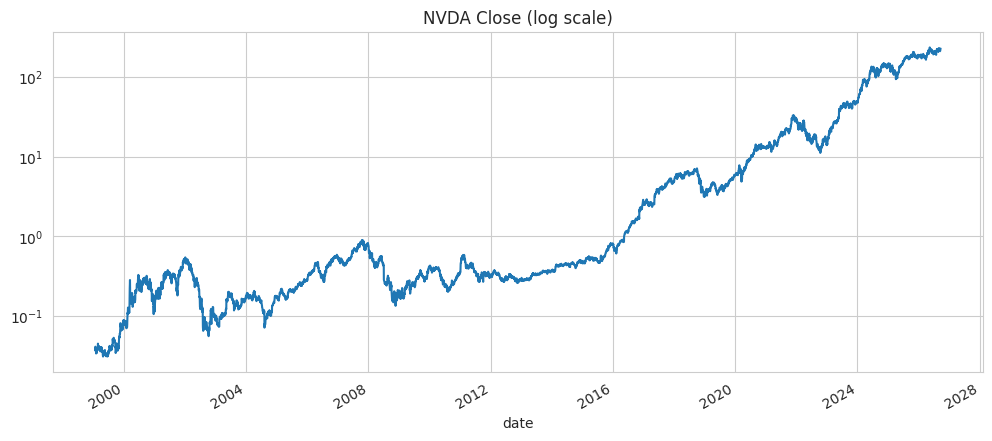

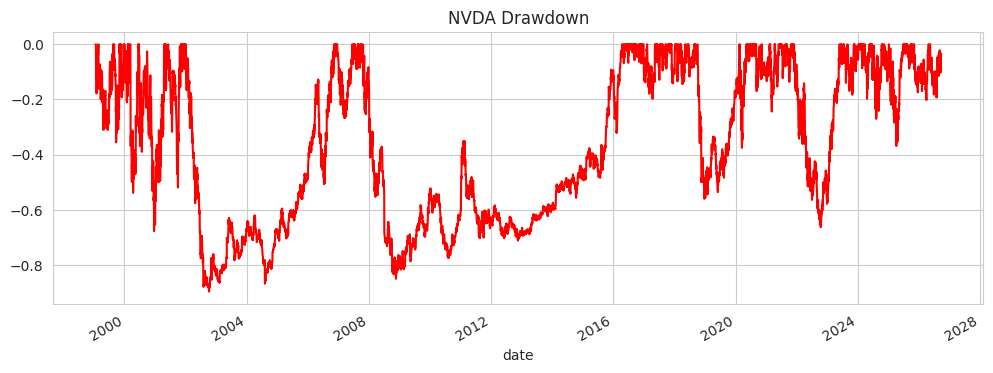

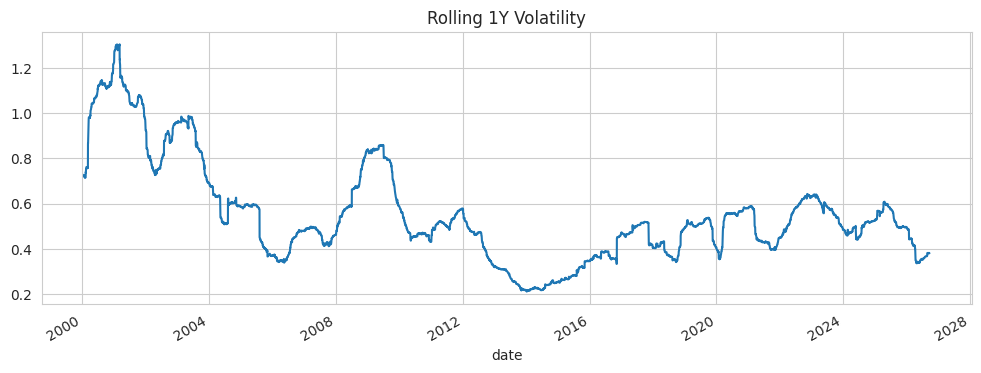

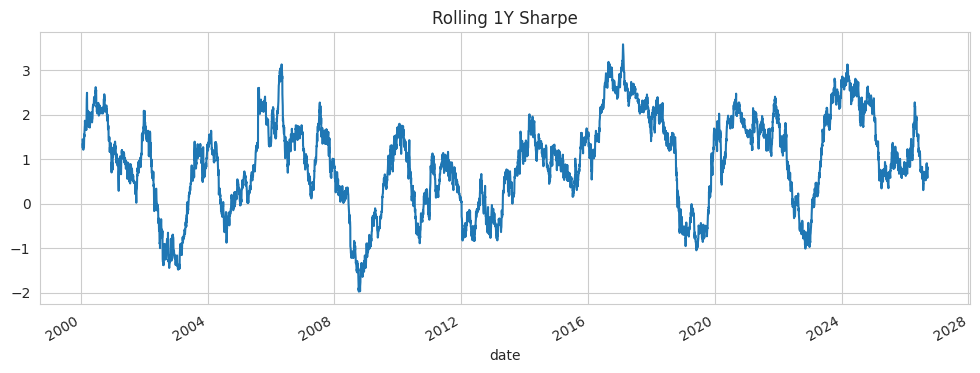

In [13]:
import os
# Ensure output directory exists
os.makedirs("charts", exist_ok=True)

# 1. Log-scale price
plt.figure(figsize=(12,5))
raw["close"].plot(logy=True, title="NVDA Close (log scale)")
plt.savefig("charts/log_price.png", dpi=300, bbox_inches="tight")
plt.show()

# 2. Drawdown
plt.figure(figsize=(12,4))
cum = (1 + raw["ret"].fillna(0)).cumprod()
dd = cum / cum.cummax() - 1
dd.plot(color="red", title="NVDA Drawdown")
plt.savefig("charts/drawdown.png", dpi=300, bbox_inches="tight")
plt.show()

# 3. Rolling 1-year volatility
plt.figure(figsize=(12,4))
(raw["ret"].rolling(252).std() * np.sqrt(252)).plot(title="Rolling 1Y Volatility")
plt.savefig("charts/rolling_volatility.png", dpi=300, bbox_inches="tight")
plt.show()

# 4. Rolling 1-year Sharpe
plt.figure(figsize=(12,4))
roll = raw["ret"].rolling(252)
((roll.mean()*252 - rf) / (roll.std()*np.sqrt(252))).plot(title="Rolling 1Y Sharpe")
plt.savefig("charts/rolling_sharpe.png", dpi=300, bbox_inches="tight")
plt.show()

## Chart takeaways

**Price (log scale):** On a log scale, NVDA's price rose from about 0.04 to over 200, but most of the gain came after 2015. The 2000 to 2015 period was volatile with long sideways stretches.

**Drawdown:** NVDA suffered three drawdowns deeper than 60% (early 2000s, 2008, and 2022). The two early ones took years to recover from, while recent pullbacks have been shallower and shorter.

**Rolling volatility:** NVDA's one-year volatility peaked near 130% in 2001 and spiked again to about 85% in 2009. It bottomed near 22% in 2014 and has since stayed between roughly 35% and 65%.

**Rolling Sharpe:** NVDA's risk-adjusted performance is highly unstable. The one-year Sharpe ratio ranged from about -2 to +3.5 and turned negative in 2002, 2008, 2012, 2018 and 2022. Strong periods were often followed by weak ones, so any single period's Sharpe is a poor guide to the next.

In [7]:
dd_df = pd.DataFrame({"dd": dd})
dd_df["episode"] = (cum == cum.cummax()).cumsum()

rows = []
episodes = list(dd_df.groupby("episode"))
for i, (ep, g) in enumerate(episodes):
    trough_date = g["dd"].idxmin()
    depth = g["dd"].min()
    peak_date = g.index[0]
    # recovery = first day of the next episode (a new high)
    rec_date = episodes[i + 1][1].index[0] if i + 1 < len(episodes) else pd.NaT
    rows.append([peak_date, trough_date, depth, rec_date])

dd_table = pd.DataFrame(rows, columns=["Peak", "Trough", "Depth", "Recovered"])
dd_table["Days peak to trough"] = (dd_table["Trough"] - dd_table["Peak"]).dt.days
dd_table["Days to recover"] = (dd_table["Recovered"] - dd_table["Trough"]).dt.days
dd_table.sort_values("Depth").head(5)

,Peak,Trough,Depth,Recovered,Days peak to trough,Days to recover
47,2002-01-03,2002-10-09,-0.897224,2006-11-13,279,1496.0
78,2007-10-17,2008-11-20,-0.850784,2016-04-15,400,2703.0
30,2000-06-21,2000-12-21,-0.677628,2001-04-20,183,120.0
279,2021-11-29,2022-10-14,-0.663351,2023-05-25,319,223.0
201,2018-10-01,2018-12-24,-0.560385,2020-02-14,84,417.0


## Worst drawdowns

NVDA fell more than 60% four times. The deepest fall was -89.7% (January to October 2002), and the 2007 to 2008 fall of -85.1% took the longest to recover: about 7.4 years from the trough to a new high. More recent drawdowns were shallower and recovered faster, such as -66.3% in 2022, which recovered in about 7 months.

| Peak | Trough | Depth | Trough to new high | Context |
|---|---|---|---|---|
| 2002-01-03 | 2002-10-09 | -89.7% | 4.1 years | Dot-com bust and tech selloff |
| 2007-10-17 | 2008-11-20 | -85.1% | 7.4 years | Global financial crisis |
| 2000-06-21 | 2000-12-21 | -67.8% | 4 months | Start of the dot-com bust |
| 2021-11-29 | 2022-10-14 | -66.3% | 7.3 months | Fed rate hikes and tech selloff |
| 2018-10-01 | 2018-12-24 | -56.0% | 13.7 months | Crypto-demand collapse and Q4 2018 market selloff |

Note: Brief rebound; the stock fell again into 2002, so the 2000 and 2002 episodes are best read as one bust.

In [8]:
!pip install yfinance -q
import yfinance as yf

spy = yf.download("SPY", start="1999-01-22", end="2026-09-22",
                  auto_adjust=True, progress=False)["Close"].squeeze()
spy_ret = spy.pct_change()

both = pd.concat([raw["ret"], spy_ret], axis=1, join="inner").dropna()
both.columns = ["nvda", "spy"]

beta = both.cov().iloc[0, 1] / both["spy"].var()
corr = both.corr().iloc[0, 1]
print(f"Beta: {beta:.2f}   Correlation: {corr:.2f}")

compare = pd.DataFrame({"NVDA": metrics(both["nvda"]), "SPY": metrics(both["spy"])})
compare

Beta: 1.64   Correlation: 0.53


,NVDA,SPY
Ann. return,0.370921,0.087783
Ann. vol,0.591707,0.192039
Sharpe,0.576166,0.300893
Max DD,-0.897224,-0.551894
VaR 95%,-0.052454,-0.018631
CVaR 95%,-0.079327,-0.028747


1995    0.63
2000    2.01
2005    1.39
2010    1.42
2015    1.67
2020    1.79
2025    1.88
dtype: float64


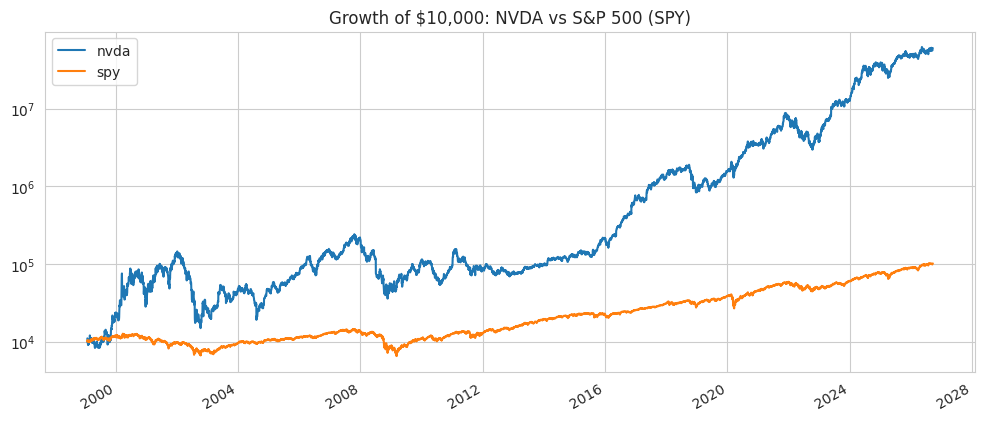

In [9]:
# Beta by 5-year era
era_b = both.index.year // 5 * 5
beta_by_era = both.groupby(era_b).apply(lambda g: g.cov().iloc[0, 1] / g["spy"].var())
print(beta_by_era.round(2))

# Growth of $10,000
growth = 10000 * (1 + both).cumprod()
growth.plot(figsize=(12, 5), logy=True, title="Growth of $10,000: NVDA vs S&P 500 (SPY)")
plt.savefig(
    "charts/growth_10k.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## NVDA vs the S&P 500

NVDA returned 37.1% a year versus 8.8% for SPY, but with volatility of 59.2% versus 19.2%. Its Sharpe ratio (0.58 vs 0.30) shows the extra return more than compensated for the extra risk, though the worst drawdown was far deeper (-89.7% vs -55.2%). Beta versus SPY is 1.64 with a correlation of 0.53, so NVDA amplifies market moves but also has a large company-specific component. Rolling beta by era fell from 2.0 in 2000 to 2004 to about 1.4 in 2005 to 2014, then rose to 1.88 in 2025 to 2026.

In [10]:
final = growth.iloc[-1]
print(f"NVDA: ${final['nvda']:,.0f}")
print(f"SPY:  ${final['spy']:,.0f}")
print(f"NVDA / SPY: {final['nvda']/final['spy']:.0f}x")

NVDA: $60,607,036
SPY:  $102,054
NVDA / SPY: 594x


## Conclusions

1. **High risk, higher reward.** NVDA's volatility was about three times the market's, and its worst drawdown (-89.7% in 2002) was far deeper than the S&P 500's (-55.2%). Even so, its Sharpe ratio was about double.
2. **Risk has changed over time.** Volatility fell from 90% in the early 2000s to about 45% recently, while risk-adjusted returns improved sharply from 2015 onward.
3. **Market sensitivity has grown.** Beta rose from about 1.4 (2005 to 2014) to 1.88 (2025 to 2026).
4. **Drawdowns were severe.** The stock fell more than 60% four times, with the deepest falls in 2002 and 2008.
5. **Long-run outcome.** $10,000 invested in January 1999 grew to about $60.6 million by September 2026, versus about $102,000 for the S&P 500 (SPY). This is a hindsight result for one of the market's biggest winners, not a realistic expectation.

## Limitations
- **Survivorship bias:** NVDA is a famous winner, so its history flatters the results.
- **Single stock:** this is not a diversified portfolio.
- **Assumed risk-free rate:** a flat 3% was used for all years.
- **Price basis:** NVDA's dividend adjustment is unspecified while SPY's is total-return adjusted.
- **Past performance does not predict future results.**

In [11]:
import os
import matplotlib.pyplot as plt

os.makedirs("charts", exist_ok=True)

for i, fig_num in enumerate(plt.get_fignums(), start=1):
    fig = plt.figure(fig_num)
    fig.savefig(
        f"charts/chart_{i}.png",
        dpi=300,
        bbox_inches="tight"
    )

print("Charts saved successfully!")

Charts saved successfully!


In [14]:
# Zip the charts folder containing all 5 images
!zip -o -r nvda_charts.zip charts

from google.colab import files
files.download("nvda_charts.zip")

updating: charts/ (stored 0%)
updating: charts/growth_10k.png (deflated 10%)
updating: charts/rolling_volatility.png (deflated 10%)
  adding: charts/rolling_sharpe.png (deflated 6%)
  adding: charts/drawdown.png (deflated 8%)
  adding: charts/log_price.png (deflated 13%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>